# Assignment 4: Pizza vs. Sushi — A Binary Image Classifier with ConvNets

**OPIM 5509: Introduction to Deep Learning · University of Connecticut · Dr. Dave Wanik**

---

## 1. Problem Description

Food-logging and calorie-tracking apps (MyFitnessPal, Lose It!, Noom) increasingly let users *photograph* a meal instead of typing it in, and the first step in that pipeline is recognizing **what kind of food is in the picture**. In this notebook I build a binary image classifier that tells apart two visually distinct but very popular dishes: **pizza** and **sushi**. A model like this could auto-tag meal photos, route images to the right nutrition-estimation model, or help a delivery platform check that restaurant menu photos are filed under the right cuisine. The two classes are a good testbed because each has wide internal variety (pepperoni vs. deep-dish vs. veggie pizza; nigiri vs. maki vs. sushi platters), photographed from many angles, under different lighting and on different backgrounds. The images come from **Wikimedia Commons**: I wrote a reproducible script (`scripts/get_images.py`, in the same GitHub repo) that searches Commons with several queries per class, keeps only files whose title actually mentions the class, removes tiny, unreadable and duplicate files, and resizes everything to ≤ 400 px. I then reviewed contact sheets by hand and removed off-topic images (people, storefronts, receipts, word art), leaving **241 pizza and 230 sushi** photos. The cleaned images are zipped and hosted in a public GitHub repo, so this notebook downloads them with `wget`, with no Google Drive needed. I then split the data into train / validation / test folders, train a **vanilla ConvNet** from scratch with early stopping, and evaluate it on every partition with a classification report and confusion matrix. Finally, I go above and beyond with **data augmentation + dropout**, **VGG16 transfer learning**, and **Grad-CAM** to see what the model is actually looking at.

## 2. Setup

Imports, a fixed random seed (**5509**) for Python, NumPy and TensorFlow so results are as reproducible as possible, and a quick check that a GPU is attached (*Runtime → Change runtime type → GPU*).

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # hide TensorFlow's C++ info/warning chatter
import glob
import math
import random
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.applications import VGG16
from sklearn.metrics import classification_report, confusion_matrix

tf.get_logger().setLevel("ERROR")          # hide harmless retracing warnings

# ---- reproducibility: same seed everywhere ----
SEED = 5509
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU available:", gpus if gpus else "NO - switch Runtime > Change runtime type > GPU")

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Data Download (Route B: bring your own zip)

The dataset lives as `my_images.zip` in my public GitHub repo, so anyone can fetch it **without logging in or mounting Drive**. The zip has one top-level folder per class: `pizza/` and `sushi/`.

`wget` downloads the zip and `unzip -o` extracts it into `images/` (overwriting if the cell is re-run).

In [2]:
# start clean so "Run all" behaves the same every time
!rm -rf images data my_images.zip

# download the zip from the public GitHub repo (raw URL = direct file link)
!wget -q -O my_images.zip https://raw.githubusercontent.com/UdayAnalyst/OPIM5509-A4/main/my_images.zip
# extract into images/  ->  images/pizza/*.jpg and images/sushi/*.jpg
!unzip -q -o my_images.zip -d images

!ls images

pizza  sushi


In [3]:
# how many images did we get per class?
for cls in sorted(os.listdir("images")):
    folder = os.path.join("images", cls)
    if os.path.isdir(folder):
        print(f"{cls:10s} {len(os.listdir(folder)):4d} images")

pizza       241 images
sushi       230 images


## 4. Quality Control (before splitting)

Scraped images are messy: HTML error pages saved as `.jpg`, truncated downloads, tiny thumbnails. A single unreadable file will crash `flow_from_directory` halfway through training. My local script already cleaned the data, but the professor's helper below runs the check again **inside the notebook** as a safety net. It deletes anything under 4 KB or anything PIL can't verify, then reports how many images survived per class (and warns if any class drops below 100).

In [4]:
def clean_image_folder(src="images", min_bytes=4096):
    """Delete anything PIL cannot decode, then report what survived per class."""
    kept = {}
    for cls in sorted(os.listdir(src)):
        folder = os.path.join(src, cls)
        if not os.path.isdir(folder):
            continue
        good = 0
        bad = 0
        for f in sorted(glob.glob(os.path.join(folder, "*"))):
            if os.path.getsize(f) < min_bytes:   # thumbnails and truncated downloads
                os.remove(f)
                bad = bad + 1
                continue
            try:
                img = Image.open(f)
                img.verify()                     # verify() catches corruption without decoding pixels
                good = good + 1
            except Exception:
                os.remove(f)
                bad = bad + 1
        kept[cls] = good
        print(f"{cls:28s} kept={good:4d}  deleted={bad:3d}")
    return kept

counts = clean_image_folder()
print()
for cls in counts:
    if counts[cls] < 100:
        print(f"WARNING {cls}: only {counts[cls]} usable images - the assignment asks for 100+ per class")

pizza                        kept= 241  deleted=  0
sushi                        kept= 230  deleted=  0



## 5. Train / Validation / Test Split

Keras infers labels from folder names, so I need `data/{train,validation,test}/{pizza,sushi}/`. The professor's `split_dataset` helper shuffles each class with seed 5509 and splits **70% train / 15% validation / 15% test**. Splitting *per class* (stratified) keeps the class balance the same in every partition.

In [5]:
def split_dataset(src="images", dst="data", train=0.7, val=0.15, seed=5509):
    """images/<class>/* -> data/{train,validation,test}/<class>/* (lowercase class names)."""
    random.seed(seed)
    exts = (".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp")
    for cls in sorted(os.listdir(src)):
        if not os.path.isdir(os.path.join(src, cls)):   # skip stray files (Bing leaves some)
            continue
        files = []
        for f in glob.glob(os.path.join(src, cls, "*")):
            if f.lower().endswith(exts):
                files.append(f)
        if not files:
            print(f"{cls}: no images, skipped")
            continue
        random.shuffle(files)
        n_va = max(1, int(len(files) * val))             # never leave validation or test empty
        n_te = max(1, len(files) - int(len(files) * train) - n_va)
        n_tr = len(files) - n_va - n_te
        parts = {}
        parts["train"] = files[:n_tr]
        parts["validation"] = files[n_tr:n_tr + n_va]
        parts["test"] = files[n_tr + n_va:]
        if min(n_tr, n_va, n_te) < 10:
            print(f"WARNING {cls}: only {len(files)} images - fine for a smoke test, but you need 100+ per class")
        name = cls.lower().replace(" ", "_")
        for part in parts:
            out = os.path.join(dst, part, name)
            os.makedirs(out, exist_ok=True)
            for f in parts[part]:
                shutil.copy2(f, out)
        print(f"{name:20s} total={len(files):4d}  train={n_tr}  validation={n_va}  test={len(files) - n_tr - n_va}")

shutil.rmtree("data", ignore_errors=True)   # re-running the cell should not double-copy files
split_dataset()

pizza                total= 241  train=168  validation=36  test=37
sushi                total= 230  train=161  validation=34  test=35


### Folder paths and a sanity check

Count the files in every split/class folder to confirm nothing leaked or went missing.

In [6]:
train_dir = "data/train"
validation_dir = "data/validation"
test_dir = "data/test"

# file count in every split / class folder
rows = []
for split_name in ["train", "validation", "test"]:
    for cls in sorted(os.listdir(os.path.join("data", split_name))):
        n = len(os.listdir(os.path.join("data", split_name, cls)))
        rows.append({"split": split_name, "class": cls, "images": n})
split_counts = pd.DataFrame(rows).pivot(index="split", columns="class", values="images")
split_counts = split_counts.loc[["train", "validation", "test"]]   # keep a logical row order
split_counts["total"] = split_counts.sum(axis=1)
split_counts

class,pizza,sushi,total
split,,,
train,168,161,329
validation,36,34,70
test,37,35,72


### Look at the data

Always eyeball a few images per class. Are these really what we think they are? Below are 6 random training images per class.

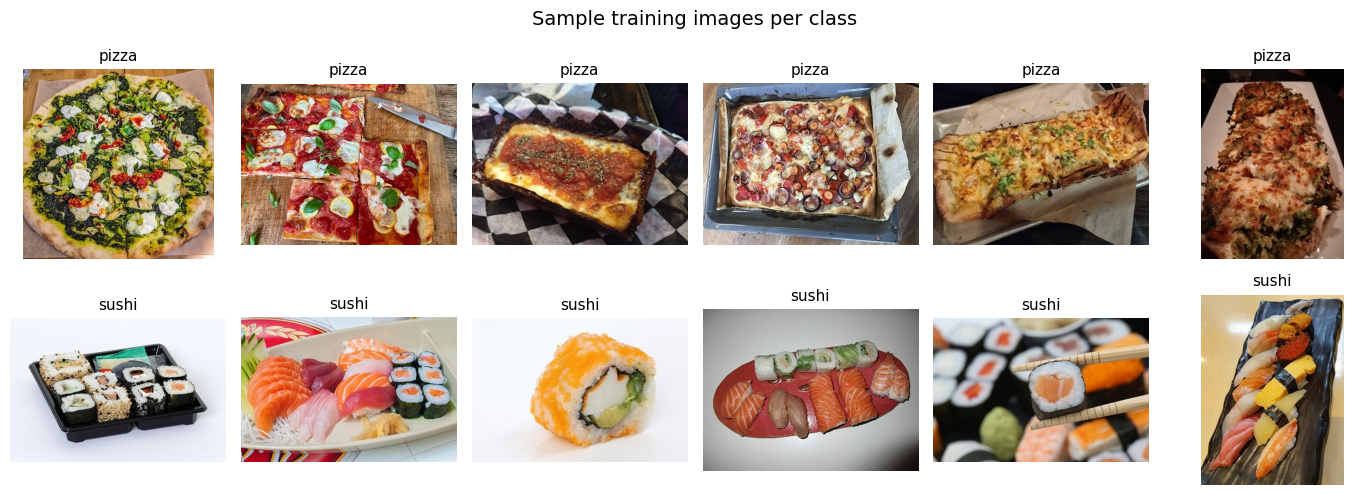

In [7]:
classes = sorted(os.listdir(train_dir))
n_show = 6   # images per class

plt.figure(figsize=(14, 5))
for row, cls in enumerate(classes):
    files = sorted(glob.glob(os.path.join(train_dir, cls, "*")))
    sample = random.sample(files, n_show)              # random but reproducible (seeded)
    for col, f in enumerate(sample):
        plt.subplot(len(classes), n_show, row * n_show + col + 1)
        plt.imshow(Image.open(f).convert("RGB"))
        plt.title(cls, fontsize=11)
        plt.axis("off")
plt.suptitle("Sample training images per class", fontsize=14)
plt.tight_layout()
plt.show()

## 6. Data Generators

Same recipe as cats vs. dogs: `ImageDataGenerator(rescale=1./255)` scales pixels from 0–255 to 0–1, every image is resized to **150×150**, batches of **20**, and `class_mode="binary"` gives a single 0/1 label. The **test generator uses `shuffle=False`** so predictions line up with `test_generator.classes`.

In [8]:
datagen = ImageDataGenerator(rescale=1./255)   # no augmentation for the vanilla model
batch_size = 20
img_size = (150, 150)

train_generator = datagen.flow_from_directory(train_dir, target_size=img_size,
                                              batch_size=batch_size, class_mode="binary",
                                              seed=SEED)
validation_generator = datagen.flow_from_directory(validation_dir, target_size=img_size,
                                                   batch_size=batch_size, class_mode="binary",
                                                   seed=SEED)
test_generator = datagen.flow_from_directory(test_dir, target_size=img_size,
                                             batch_size=batch_size, class_mode="binary",
                                             shuffle=False)   # keep order for evaluation

print(train_generator.class_indices)   # alphabetical: first class = 0, second class = 1
class_names = list(train_generator.class_indices)

Found 329 images belonging to 2 classes.
Found 70 images belonging to 2 classes.
Found 72 images belonging to 2 classes.
{'pizza': 0, 'sushi': 1}


## 7. Vanilla ConvNet

Four `Conv2D → MaxPooling2D` blocks with increasing filters (32 → 64 → 128 → 128) learn more and more abstract features (edges → textures → parts such as rice, crust or toppings) while shrinking the spatial size. `Flatten → Dense(512)` combines them, and a single **sigmoid** unit outputs P(class 1). The loss is **binary cross-entropy** and the optimizer is **RMSprop with lr = 1e-4** (the Chollet cats-vs-dogs setup).

In [9]:
def build_vanilla_convnet(dropout=0.0):
    # dropout=0.0 -> the pure vanilla model; the augmented model in Section 11 reuses this with 0.5
    model = keras.Sequential([
        keras.Input(shape=(150, 150, 3)),
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation="relu", name="last_conv"),   # named for Grad-CAM
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dropout(dropout),                                           # no-op when dropout=0
        layers.Dense(512, activation="relu"),
        layers.Dense(1, activation="sigmoid"),                             # P(class 1)
    ])
    model.compile(loss="binary_crossentropy",
                  optimizer=keras.optimizers.RMSprop(learning_rate=1e-4),
                  metrics=["accuracy"])
    return model

tf.random.set_seed(SEED)   # same initial weights every run
model = build_vanilla_convnet()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,453,121 (13.17 MB)

 Trainable params: 3,453,121 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Training

- **Soft-coded steps:** `steps_per_epoch = ceil(n_train / batch_size)` so each epoch sees every image once, whatever the dataset size.
- **EarlyStopping** watches `val_loss`, stops after 5 epochs without improvement, and **restores the best weights**, so we never keep an overfit model.
- The trained model is saved in the native **`.keras`** format.

In [10]:
steps_per_epoch = math.ceil(train_generator.samples / batch_size)
validation_steps = math.ceil(validation_generator.samples / batch_size)
print("steps_per_epoch:", steps_per_epoch, "| validation_steps:", validation_steps)

early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)

history = model.fit(train_generator,
                    steps_per_epoch=steps_per_epoch,
                    epochs=50,                       # upper bound; early stopping decides
                    validation_data=validation_generator,
                    validation_steps=validation_steps,
                    callbacks=[early_stop],
                    verbose=2)                       # one line per epoch keeps output readable

model.save("vanilla_convnet.keras")
print("Saved vanilla_convnet.keras")

steps_per_epoch: 17 | validation_steps: 4
Epoch 1/50
17/17 - 19s - 1s/step - accuracy: 0.5380 - loss: 0.6933 - val_accuracy: 0.7143 - val_loss: 0.6771
Epoch 2/50
17/17 - 4s - 240ms/step - accuracy: 0.6657 - loss: 0.6509 - val_accuracy: 0.5143 - val_loss: 0.6828
Epoch 3/50
17/17 - 1s - 76ms/step - accuracy: 0.6626 - loss: 0.6034 - val_accuracy: 0.7000 - val_loss: 0.5954
Epoch 4/50
17/17 - 1s - 74ms/step - accuracy: 0.7356 - loss: 0.5384 - val_accuracy: 0.6857 - val_loss: 0.5665
Epoch 5/50
17/17 - 1s - 58ms/step - accuracy: 0.7052 - loss: 0.5466 - val_accuracy: 0.6857 - val_loss: 0.5557
Epoch 6/50
17/17 - 1s - 48ms/step - accuracy: 0.7538 - loss: 0.4952 - val_accuracy: 0.7143 - val_loss: 0.6161
Epoch 7/50
17/17 - 1s - 50ms/step - accuracy: 0.7477 - loss: 0.4926 - val_accuracy: 0.7000 - val_loss: 0.5473
Epoch 8/50
17/17 - 1s - 53ms/step - accuracy: 0.7660 - loss: 0.4579 - val_accuracy: 0.7286 - val_loss: 0.5261
Epoch 9/50
17/17 - 1s - 52ms/step - accuracy: 0.8055 - loss: 0.4453 - val_accu

## 9. Learning Curves

If training loss keeps falling while validation loss flattens or rises, the model is **memorizing** the training set (overfitting). The dashed line marks the epoch whose weights early stopping restored.

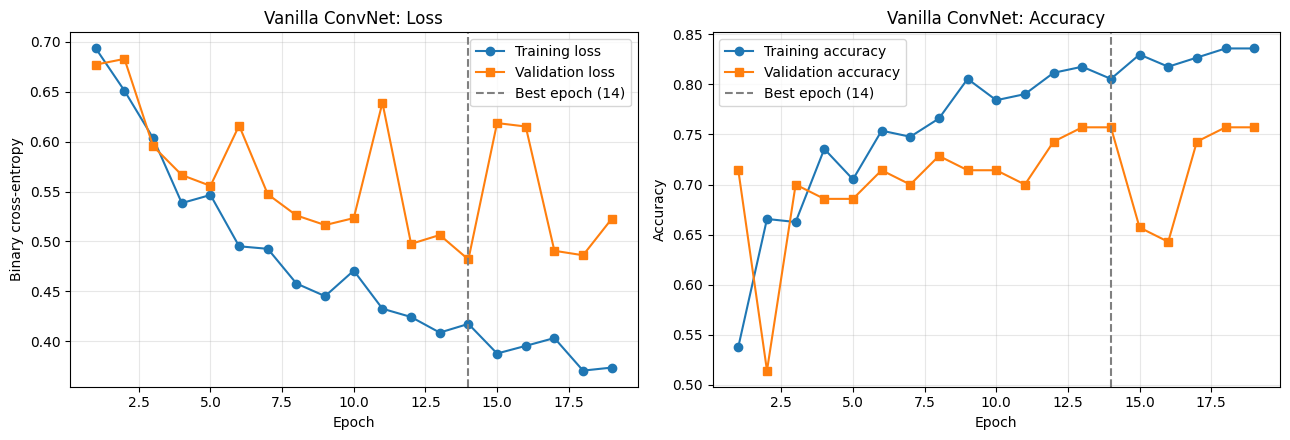

In [11]:
def plot_history(history, title):
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)
    best = int(np.argmin(h["val_loss"])) + 1          # epoch restored by early stopping

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(epochs, h["loss"], "o-", label="Training loss")
    axes[0].plot(epochs, h["val_loss"], "s-", label="Validation loss")
    axes[0].set_title(f"{title}: Loss")
    axes[0].set_ylabel("Binary cross-entropy")

    axes[1].plot(epochs, h["accuracy"], "o-", label="Training accuracy")
    axes[1].plot(epochs, h["val_accuracy"], "s-", label="Validation accuracy")
    axes[1].set_title(f"{title}: Accuracy")
    axes[1].set_ylabel("Accuracy")

    for ax in axes:
        ax.axvline(best, color="gray", linestyle="--", label=f"Best epoch ({best})")
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.show()

plot_history(history, "Vanilla ConvNet")

## 10. Evaluation

For clean scores I evaluate on **non-shuffled** copies of the train and validation generators, so every image is scored exactly once and in a fixed order. The same function is reused for every model in Section 11, so all comparisons are apples to apples.

In [12]:
# non-shuffled generators for scoring (training used the shuffled ones)
train_eval_generator = datagen.flow_from_directory(train_dir, target_size=img_size,
                                                   batch_size=batch_size, class_mode="binary",
                                                   shuffle=False)
validation_eval_generator = datagen.flow_from_directory(validation_dir, target_size=img_size,
                                                        batch_size=batch_size, class_mode="binary",
                                                        shuffle=False)

def score_partitions(model):
    # loss and accuracy on every partition -> small DataFrame
    rows = []
    for name, gen in [("train", train_eval_generator),
                      ("validation", validation_eval_generator),
                      ("test", test_generator)]:
        loss, acc = model.evaluate(gen, steps=math.ceil(gen.samples / batch_size), verbose=0)
        rows.append({"partition": name, "loss": round(loss, 4), "accuracy": round(acc, 4)})
    return pd.DataFrame(rows).set_index("partition")

vanilla_scores = score_partitions(model)
vanilla_scores

Found 329 images belonging to 2 classes.
Found 70 images belonging to 2 classes.


,loss,accuracy
partition,,
train,0.3651,0.8359
validation,0.4820,0.7571
test,0.4936,0.7083


### Test-set classification report and confusion matrix

Probabilities ≥ 0.5 are predicted as class 1. Because `test_generator` was not shuffled, `test_generator.classes` holds the true labels in the same order as the predictions.

===== Vanilla ConvNet: classification report (TEST) =====
              precision    recall  f1-score   support

       pizza      0.667     0.865     0.753        37
       sushi      0.792     0.543     0.644        35

    accuracy                          0.708        72
   macro avg      0.729     0.704     0.699        72
weighted avg      0.727     0.708     0.700        72



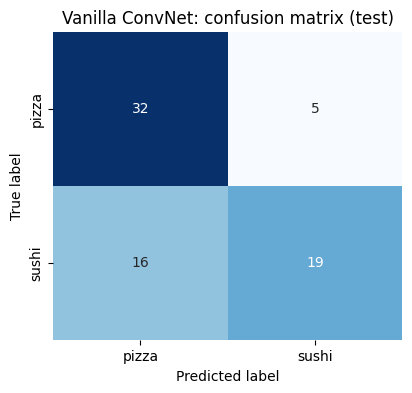

In [13]:
def test_report(model, title):
    test_generator.reset()                                   # start from the first batch
    probs = model.predict(test_generator, steps=math.ceil(test_generator.samples / batch_size),
                          verbose=0).ravel()
    y_pred = (probs >= 0.5).astype(int)                      # threshold at 0.5
    y_true = test_generator.classes

    print(f"===== {title}: classification report (TEST) =====")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(4.5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"{title}: confusion matrix (test)")
    plt.show()
    return probs, y_pred

vanilla_probs, vanilla_pred = test_report(model, "Vanilla ConvNet")

### Which test images did the vanilla model get wrong?

Looking at the mistakes is the fastest way to understand *why* a model fails.

21 of 72 test images misclassified


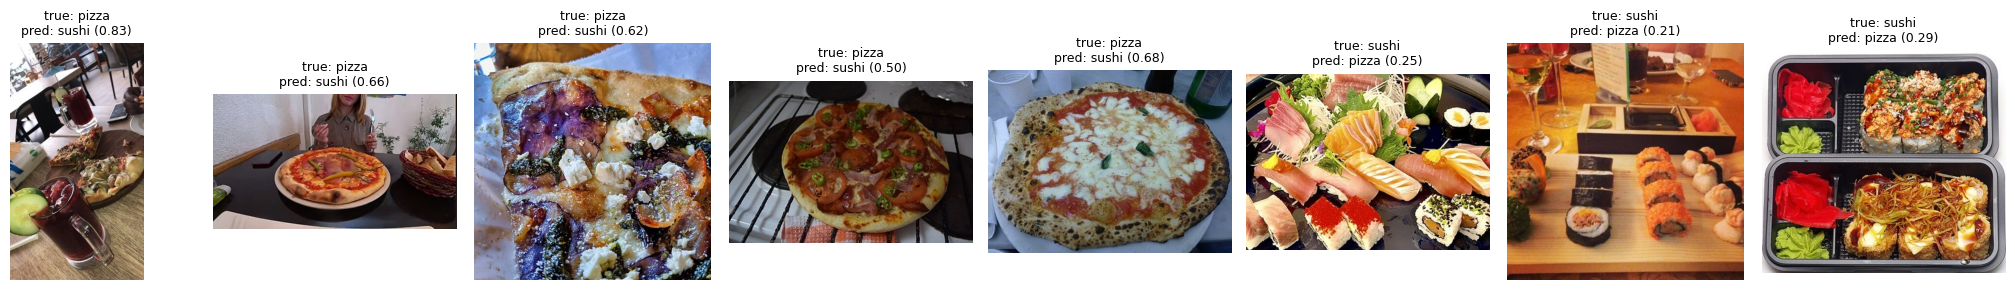

In [14]:
wrong = np.where(vanilla_pred != test_generator.classes)[0]
print(f"{len(wrong)} of {test_generator.samples} test images misclassified")

n = min(8, len(wrong))
if n > 0:
    plt.figure(figsize=(2.6 * n, 3))
    for k, idx in enumerate(wrong[:n]):
        path = os.path.join(test_dir, test_generator.filenames[idx])
        plt.subplot(1, n, k + 1)
        plt.imshow(Image.open(path).convert("RGB"))
        true_name = class_names[test_generator.classes[idx]]
        pred_name = class_names[vanilla_pred[idx]]
        plt.title(f"true: {true_name}\npred: {pred_name} ({vanilla_probs[idx]:.2f})", fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

### Interpreting the vanilla results

- **Overfitting:** the vanilla ConvNet reached **83.6%** training accuracy but only **75.7%** validation and **70.8%** test accuracy, a **12.8-point** train–test gap. The loss curves show it clearly: training loss keeps falling to about 0.37, while validation loss bottoms out at **epoch 14** (0.48) and then jumps around (0.62 at epochs 15–16). Early stopping restored the epoch-14 weights, so the saved model is the least overfit one.
- **Which class is confused more: sushi.** The confusion matrix shows **16 sushi → pizza** errors but only **5 pizza → sushi** errors. Sushi recall is just **54%**, against **86%** for pizza. In other words, the model has learned a "when in doubt, say pizza" bias. Colorful sashimi platters and bento boxes with red pickled ginger seem to look "pizza-like" (red, round, busy) to a small network trained from scratch.
- **The misclassified images are hard or unusual:** a pizza photographed from across a restaurant table with a big glass of wine in front, a purple-potato pizza, and a pizza sitting on an oven rack. Most of the frame isn't pizza at all, which tells me the model leans on global color and texture more than on the shape of the food.
- **Noisy validation curve:** with only 70 validation images, one image is worth 1.4 accuracy points. That is why the validation curve is so jagged, and why `patience=5` matters.
- **Bottom line:** 70.8% beats a coin flip, but it is not a usable classifier. That motivates the regularization and transfer-learning experiments below.


## 11. Above & Beyond

### 11a. Vanilla ConvNet + Data Augmentation + Dropout

With only a few hundred training images, the model sees the same pictures every epoch. **Data augmentation** creates random rotations, shifts, shears, zooms and flips **on the training set only**, so the network never sees exactly the same image twice. **Dropout(0.5)** randomly silences half the flattened features during training. Both are regularizers that should shrink the train–validation gap. Validation and test images are **not** augmented, because we want to score the model on real, unaltered photos.

Found 329 images belonging to 2 classes.


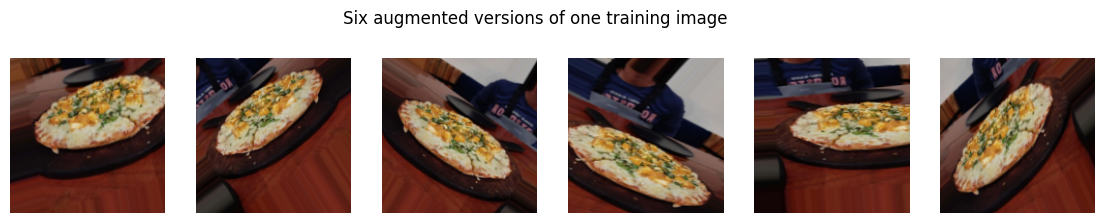

In [15]:
aug_datagen = ImageDataGenerator(rescale=1./255,
                                 rotation_range=40,        # degrees
                                 width_shift_range=0.2,    # fraction of width
                                 height_shift_range=0.2,
                                 shear_range=0.2,
                                 zoom_range=0.2,
                                 horizontal_flip=True,     # a flipped pizza is still a pizza
                                 fill_mode="nearest")

train_aug_generator = aug_datagen.flow_from_directory(train_dir, target_size=img_size,
                                                      batch_size=batch_size, class_mode="binary",
                                                      seed=SEED)

# what does augmentation actually do? the same training image, 6 random transformations
sample_path = sorted(glob.glob(os.path.join(train_dir, class_names[0], "*")))[0]
x = np.array(Image.open(sample_path).convert("RGB").resize(img_size))[None, ...]   # shape (1,150,150,3)
plt.figure(figsize=(14, 2.6))
for k, batch in enumerate(aug_datagen.flow(x, batch_size=1, seed=SEED)):
    plt.subplot(1, 6, k + 1)
    plt.imshow(batch[0])
    plt.axis("off")
    if k == 5:
        break
plt.suptitle("Six augmented versions of one training image")
plt.show()

In [16]:
tf.random.set_seed(SEED)
aug_model = build_vanilla_convnet(dropout=0.5)

# augmented data is noisier, so give it a bit more patience before stopping
aug_early_stop = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1)

aug_history = aug_model.fit(train_aug_generator,
                            steps_per_epoch=math.ceil(train_aug_generator.samples / batch_size),
                            epochs=60,
                            validation_data=validation_generator,
                            validation_steps=validation_steps,
                            callbacks=[aug_early_stop],
                            verbose=2)

aug_model.save("augmented_convnet.keras")
print("Saved augmented_convnet.keras")

Epoch 1/60
17/17 - 11s - 653ms/step - accuracy: 0.4833 - loss: 0.6937 - val_accuracy: 0.6286 - val_loss: 0.6852
Epoch 2/60
17/17 - 3s - 150ms/step - accuracy: 0.5684 - loss: 0.6826 - val_accuracy: 0.6143 - val_loss: 0.6664
Epoch 3/60
17/17 - 3s - 180ms/step - accuracy: 0.6109 - loss: 0.6515 - val_accuracy: 0.6429 - val_loss: 0.6257
Epoch 4/60
17/17 - 3s - 178ms/step - accuracy: 0.6657 - loss: 0.6133 - val_accuracy: 0.6571 - val_loss: 0.6054
Epoch 5/60
17/17 - 3s - 151ms/step - accuracy: 0.7264 - loss: 0.5542 - val_accuracy: 0.6714 - val_loss: 0.6154
Epoch 6/60
17/17 - 3s - 155ms/step - accuracy: 0.6900 - loss: 0.5544 - val_accuracy: 0.6429 - val_loss: 0.5775
Epoch 7/60
17/17 - 2s - 147ms/step - accuracy: 0.6991 - loss: 0.5313 - val_accuracy: 0.6571 - val_loss: 0.5756
Epoch 8/60
17/17 - 4s - 218ms/step - accuracy: 0.7021 - loss: 0.5299 - val_accuracy: 0.6857 - val_loss: 0.7010
Epoch 9/60
17/17 - 4s - 223ms/step - accuracy: 0.7325 - loss: 0.5149 - val_accuracy: 0.6714 - val_loss: 0.5577


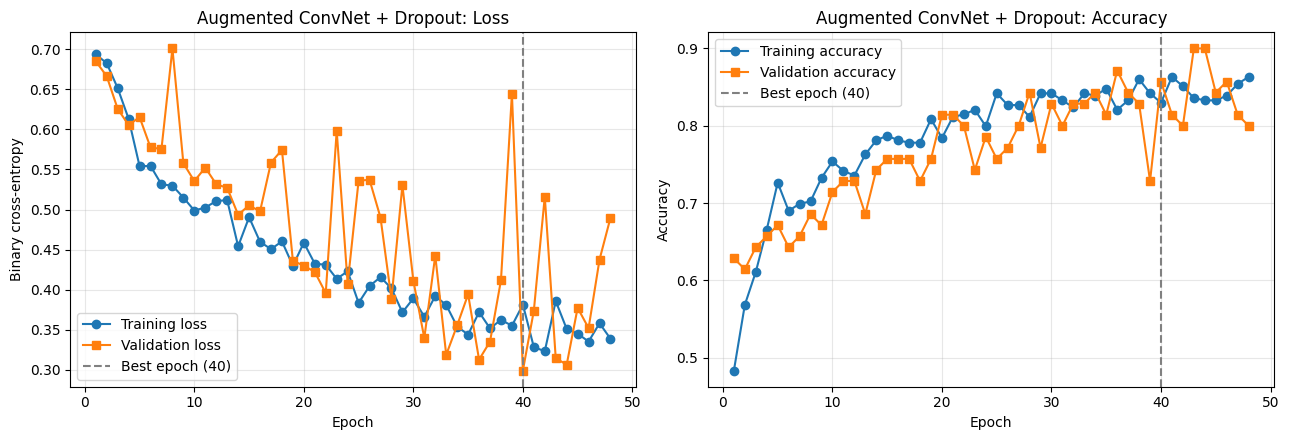

,loss,accuracy
partition,,
train,0.2795,0.8906
validation,0.2990,0.8571
test,0.3756,0.8333


In [17]:
plot_history(aug_history, "Augmented ConvNet + Dropout")
aug_scores = score_partitions(aug_model)
aug_scores

===== Augmented ConvNet + Dropout: classification report (TEST) =====
              precision    recall  f1-score   support

       pizza      0.821     0.865     0.842        37
       sushi      0.848     0.800     0.824        35

    accuracy                          0.833        72
   macro avg      0.834     0.832     0.833        72
weighted avg      0.834     0.833     0.833        72



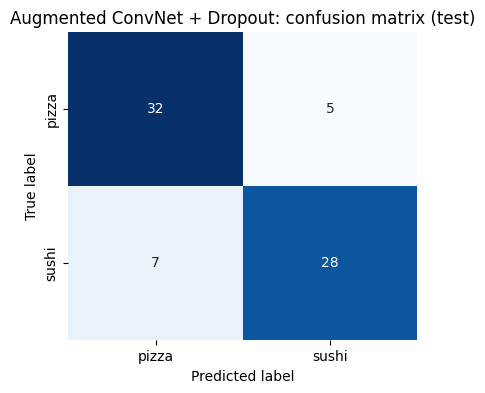

In [18]:
aug_probs, aug_pred = test_report(aug_model, "Augmented ConvNet + Dropout")

### 11b. Transfer Learning with VGG16 (frozen convolutional base)

VGG16 was trained on 1.4 million ImageNet images, including food categories such as *pizza* and plates of food, so its convolutional filters already recognize textures like melted cheese, rice grains and fish. I **freeze** the whole convolutional base (`include_top=False`, input 150×150×3) and train only a small dense head on top. That means only a few hundred thousand trainable parameters, a natural fit for a small dataset. I train it on the same augmented generator.

In [19]:
conv_base = VGG16(weights="imagenet", include_top=False, input_shape=(150, 150, 3))
conv_base.trainable = False          # freeze: keep the ImageNet features, train only the head

tf.random.set_seed(SEED)
vgg_model = keras.Sequential([
    keras.Input(shape=(150, 150, 3)),
    conv_base,                                   # output: 4 x 4 x 512 feature maps
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid"),
])
vgg_model.compile(loss="binary_crossentropy",
                  optimizer=keras.optimizers.RMSprop(learning_rate=1e-4),
                  metrics=["accuracy"])
vgg_model.summary()     # note: "Non-trainable params" = the frozen VGG16 base

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,812,353 (64.13 MB)

 Trainable params: 2,097,665 (8.00 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [20]:
vgg_early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)

vgg_history = vgg_model.fit(train_aug_generator,
                            steps_per_epoch=math.ceil(train_aug_generator.samples / batch_size),
                            epochs=30,
                            validation_data=validation_generator,
                            validation_steps=validation_steps,
                            callbacks=[vgg_early_stop],
                            verbose=2)

vgg_model.save("vgg16_transfer.keras")
print("Saved vgg16_transfer.keras")

Epoch 1/30
17/17 - 13s - 779ms/step - accuracy: 0.6778 - loss: 0.6094 - val_accuracy: 0.8714 - val_loss: 0.3977
Epoch 2/30
17/17 - 3s - 164ms/step - accuracy: 0.8207 - loss: 0.4049 - val_accuracy: 0.8714 - val_loss: 0.3369
Epoch 3/30
17/17 - 3s - 178ms/step - accuracy: 0.8541 - loss: 0.3569 - val_accuracy: 0.8857 - val_loss: 0.2964
Epoch 4/30
17/17 - 5s - 287ms/step - accuracy: 0.8450 - loss: 0.3285 - val_accuracy: 0.9000 - val_loss: 0.2732
Epoch 5/30
17/17 - 3s - 170ms/step - accuracy: 0.8511 - loss: 0.2907 - val_accuracy: 0.8571 - val_loss: 0.2689
Epoch 6/30
17/17 - 3s - 167ms/step - accuracy: 0.9088 - loss: 0.2541 - val_accuracy: 0.9143 - val_loss: 0.2501
Epoch 7/30
17/17 - 4s - 225ms/step - accuracy: 0.8936 - loss: 0.2648 - val_accuracy: 0.8857 - val_loss: 0.2460
Epoch 8/30
17/17 - 4s - 237ms/step - accuracy: 0.9088 - loss: 0.2127 - val_accuracy: 0.8857 - val_loss: 0.2388
Epoch 9/30
17/17 - 3s - 163ms/step - accuracy: 0.9179 - loss: 0.2384 - val_accuracy: 0.9000 - val_loss: 0.2287


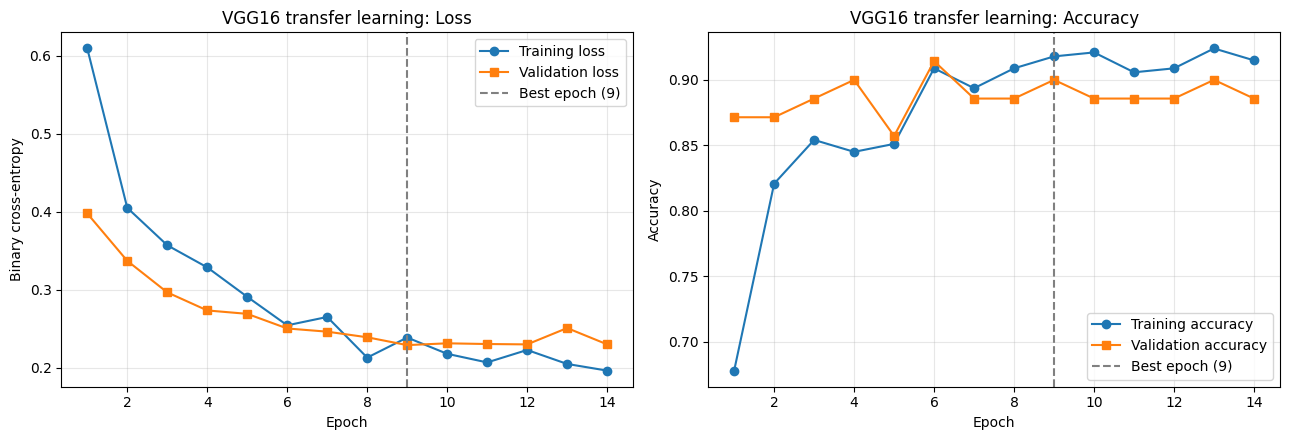

,loss,accuracy
partition,,
train,0.1222,0.9696
validation,0.2287,0.9000
test,0.1567,0.9306


In [21]:
plot_history(vgg_history, "VGG16 transfer learning")
vgg_scores = score_partitions(vgg_model)
vgg_scores

===== VGG16 transfer learning: classification report (TEST) =====
              precision    recall  f1-score   support

       pizza      0.900     0.973     0.935        37
       sushi      0.969     0.886     0.925        35

    accuracy                          0.931        72
   macro avg      0.934     0.929     0.930        72
weighted avg      0.933     0.931     0.930        72



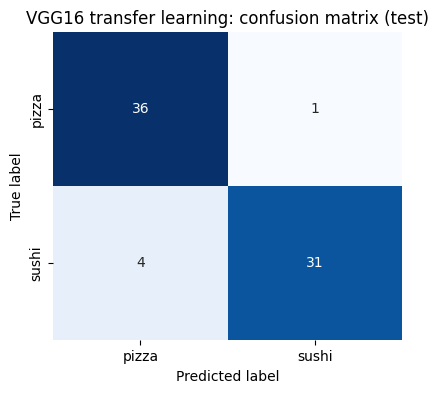

In [22]:
vgg_probs, vgg_pred = test_report(vgg_model, "VGG16 transfer learning")

### 11c. Model Comparison

All three models are scored on the same, untouched test images.

In [23]:
comparison = pd.DataFrame({
    "train_acc":      [vanilla_scores.loc["train", "accuracy"], aug_scores.loc["train", "accuracy"], vgg_scores.loc["train", "accuracy"]],
    "validation_acc": [vanilla_scores.loc["validation", "accuracy"], aug_scores.loc["validation", "accuracy"], vgg_scores.loc["validation", "accuracy"]],
    "test_acc":       [vanilla_scores.loc["test", "accuracy"], aug_scores.loc["test", "accuracy"], vgg_scores.loc["test", "accuracy"]],
    "test_loss":      [vanilla_scores.loc["test", "loss"], aug_scores.loc["test", "loss"], vgg_scores.loc["test", "loss"]],
    "epochs_trained": [len(history.history["loss"]), len(aug_history.history["loss"]), len(vgg_history.history["loss"])],
}, index=["Vanilla ConvNet", "Augmented ConvNet + Dropout", "VGG16 transfer (frozen)"])
comparison["train_test_gap"] = (comparison["train_acc"] - comparison["test_acc"]).round(4)   # overfitting signal
comparison.sort_values("test_acc", ascending=False)

,train_acc,validation_acc,test_acc,test_loss,epochs_trained,train_test_gap
VGG16 transfer (frozen),0.9696,0.9000,0.9306,0.1567,14,0.0390
Augmented ConvNet + Dropout,0.8906,0.8571,0.8333,0.3756,48,0.0573
Vanilla ConvNet,0.8359,0.7571,0.7083,0.4936,19,0.1276


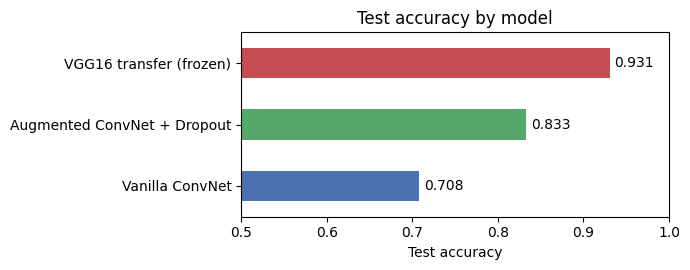

In [24]:
ax = comparison["test_acc"].plot(kind="barh", figsize=(7, 2.8), color=["#4C72B0", "#55A868", "#C44E52"])
ax.set_xlim(0.5, 1.0)                       # 0.5 = coin flip baseline
ax.set_xlabel("Test accuracy")
ax.set_title("Test accuracy by model")
for i, v in enumerate(comparison["test_acc"]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center")
plt.tight_layout()
plt.show()

### Comparison takeaways

| Model | Test accuracy | Train–test gap | Sushi recall |
|---|---|---|---|
| Vanilla ConvNet | 70.8% | 12.8 pts | 54% |
| + Augmentation & Dropout | 83.3% | 5.7 pts | 80% |
| VGG16 transfer (frozen) | **93.1%** | **3.9 pts** | **89%** |

- **Augmentation + dropout added 12.5 points** of test accuracy and cut the overfitting gap by more than half. It needed far more epochs to get there (best epoch 40 of 48, against 14 for vanilla), because every epoch shows the model new random variations.
- **Transfer learning was the clear winner.** Frozen ImageNet features got to 93.1% in only 9 epochs, with just 2.1M trainable parameters. The pretrained filters already know what cheese, rice and fish texture look like.
- **VGG16 fixed the sushi problem:** sushi recall went from 54% (vanilla) to 89%, and only 5 of 72 test images were misclassified.


### 11d. Grad-CAM: what is the custom ConvNet looking at?

**Grad-CAM** takes the gradient of the predicted score with respect to the last convolutional layer's feature maps. Feature maps that push the prediction up get more weight, and their weighted sum becomes a heat map over the image. If the model is right *for the right reason*, the heat should sit on the food itself (crust, cheese, rice, fish) and not on the plate, table or background.

I use whichever custom ConvNet (vanilla or augmented) scored higher on the test set.

Grad-CAM model: Augmented ConvNet


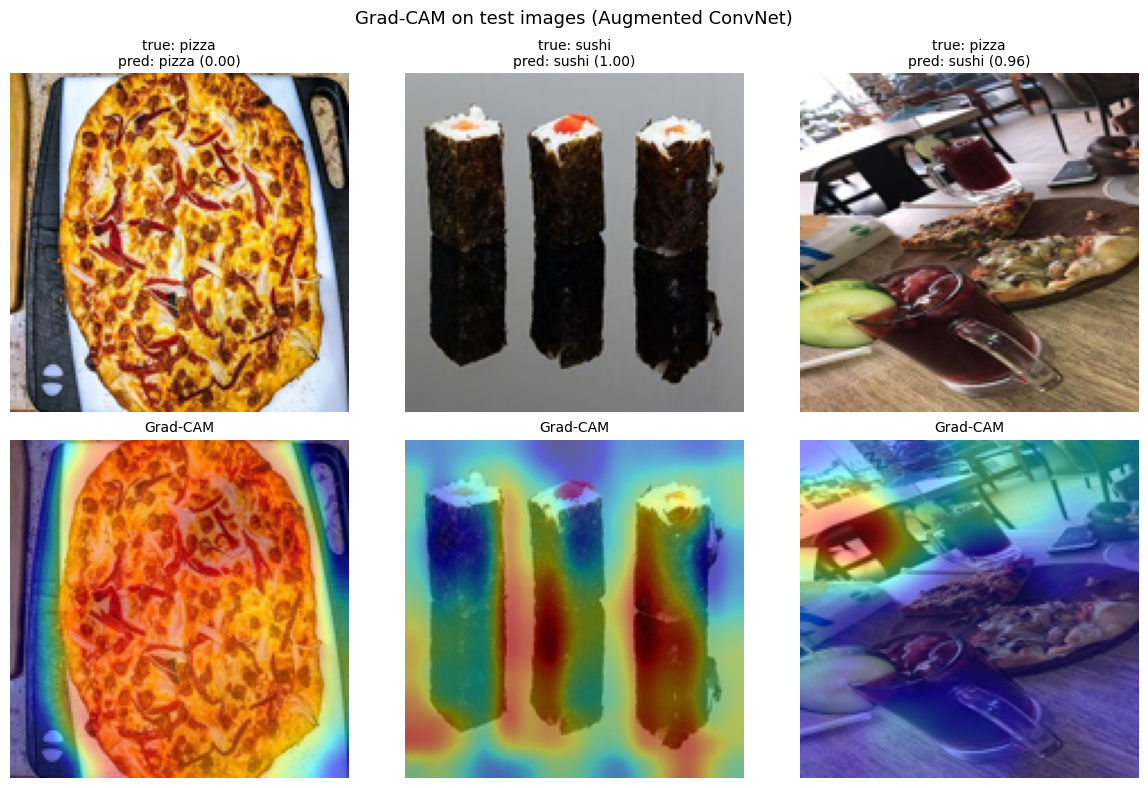

In [25]:
# pick the better of the two custom ConvNets
if comparison.loc["Augmented ConvNet + Dropout", "test_acc"] >= comparison.loc["Vanilla ConvNet", "test_acc"]:
    cam_model, cam_name, cam_probs = aug_model, "Augmented ConvNet", aug_probs
else:
    cam_model, cam_name, cam_probs = model, "Vanilla ConvNet", vanilla_probs
print("Grad-CAM model:", cam_name)

# Rebuild the forward pass with the functional API so we can read the last conv layer's output.
# The layers (and their trained weights) are reused, not copied.
inp = keras.Input(shape=(150, 150, 3))
x = inp
conv_output = None
for layer in cam_model.layers:
    x = layer(x)
    if layer.name == "last_conv":
        conv_output = x
grad_model = keras.Model(inp, [conv_output, x])

def grad_cam(img_array):
    # img_array: (1, 150, 150, 3) scaled to 0-1
    with tf.GradientTape() as tape:
        conv_maps, pred = grad_model(img_array)
        score = pred[:, 0]
        if float(score[0]) < 0.5:          # explain the class that was actually predicted
            score = 1.0 - score
    grads = tape.gradient(score, conv_maps)                 # d(score) / d(feature maps)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))         # one importance weight per channel
    cam = tf.reduce_sum(conv_maps[0] * weights, axis=-1)    # weighted sum of feature maps
    cam = tf.maximum(cam, 0) / (tf.reduce_max(cam) + 1e-8)  # ReLU + normalize to 0-1
    return cam.numpy()

# 3 test images: one confident per class + one the model got wrong (if any)
y_true = test_generator.classes
cam_pred = (cam_probs >= 0.5).astype(int)
picks = []
for c in [0, 1]:
    correct_c = np.where((y_true == c) & (cam_pred == c))[0]
    if len(correct_c) > 0:
        picks.append(correct_c[np.argmax(np.abs(cam_probs[correct_c] - 0.5))])   # most confident
wrong_idx = np.where(cam_pred != y_true)[0]
if len(wrong_idx) > 0:
    picks.append(wrong_idx[0])

plt.figure(figsize=(4 * len(picks), 8))
for k, idx in enumerate(picks):
    path = os.path.join(test_dir, test_generator.filenames[idx])
    img = np.array(Image.open(path).convert("RGB").resize(img_size)) / 255.0
    heat = grad_cam(img[None, ...].astype("float32"))
    heat = np.array(Image.fromarray(np.uint8(255 * heat)).resize(img_size)) / 255.0   # upsample to 150x150

    title = f"true: {class_names[y_true[idx]]}\npred: {class_names[cam_pred[idx]]} ({cam_probs[idx]:.2f})"
    plt.subplot(2, len(picks), k + 1)
    plt.imshow(img)
    plt.title(title, fontsize=10)
    plt.axis("off")
    plt.subplot(2, len(picks), len(picks) + k + 1)
    plt.imshow(img)
    plt.imshow(heat, cmap="jet", alpha=0.45)               # overlay heat map
    plt.title("Grad-CAM", fontsize=10)
    plt.axis("off")
plt.suptitle(f"Grad-CAM on test images ({cam_name})", fontsize=13)
plt.tight_layout()
plt.show()

### What Grad-CAM shows

- **Correct pizza (left):** the heat covers the whole pie (crust edge, cheese and toppings) and not the cutting board around it. That is right for the right reason.
- **Correct sushi (middle):** the heat sits on the dark nori-wrapped sides of the maki rolls, which is a very sushi-specific texture.
- **Wrong prediction (right):** a pizza photo that the model called **sushi with 96% confidence**. The heat is on the **glass of red drink and the table**, not on the pizza slices in the background. The model was fooled by the scene, which is exactly the "global color, not the food" weakness I suspected from the misclassified images. More tightly cropped training images, or training on bounding-box crops, would help.


## 12. What I Learned

1. **Web-scraped data can be silently poisoned, so always look at your images.** My first scrape with `icrawler` returned around 200 images per class that looked fine by the counts. A contact-sheet review showed fantasy dragons, TV-show DVD covers, cat memes and Neapolitan *ice cream* in the "sushi" and "pizza" folders. The cause was that icrawler's Bing crawler mangled multi-word queries ("dragon roll sushi" → dragons), and then Bing started throttling me and returned random results. Switching to Wikimedia Commons, with a filter that keeps a file only if its title mentions the class word, fixed it. Lesson: **file counts and `PIL.verify()` cannot tell you whether an image is the right *thing*. Only looking can.**
2. **Cleaning is an iterative loop, not a single step.** Even after two manual passes, the sample-image grid in Section 5 revealed a receipt photo labeled "sushi" and a pizza infographic. I removed them and rebuilt the zip. Small datasets amplify every mislabeled image: with 72 test images, one bad label is worth about 1.4 accuracy points.
3. **The vanilla ConvNet overfit quickly and was biased toward "pizza".** It reached 83.6% training accuracy, but validation loss bottomed out at epoch 14 and test accuracy was only 70.8%. The confusion matrix showed 16 sushi → pizza errors against just 5 pizza → sushi errors (sushi recall 54%). EarlyStopping with `restore_best_weights=True` was essential: without it I would have saved a worse, later-epoch model.
4. **Augmentation + Dropout(0.5) worked as promised:** test accuracy rose from 70.8% to **83.3%**, the train–test gap shrank from 12.8 to 5.7 points, and sushi recall rose from 54% to 80%. The price was training time (40 epochs to reach the best weights, against 14), which is why I raised its patience to 8.
5. **Transfer learning beat everything I trained from scratch.** A frozen VGG16 base plus a small dense head reached **93.1%** test accuracy (89% sushi recall, 97% pizza recall) in only 9 epochs. With a few hundred images, borrowing features learned from 1.4M ImageNet photos is far more effective than learning features from scratch.
6. **Results vary from run to run, even with seeds.** When I tested the same notebook on my laptop's CPU, the vanilla model scored 84.9% on test. On Colab's GPU it scored 70.8%. GPU operations are not bit-for-bit deterministic, and with only 72 test images a few images flipping changes accuracy by many points. Before claiming one model is better, I should average several runs or use cross-validation. That said, VGG16 scored about 93% in both runs, so the pretrained model is also the most *stable* one.
7. **Grad-CAM exposed a shortcut that accuracy alone would hide.** On the misclassified pizza, the model's attention was on a glass of red drink and the table, not on the food. Many of the errors are cluttered restaurant scenes, so the next improvements would be tighter crops of the food, more cluttered-scene training examples, and fine-tuning VGG16's top block.
